<a href="https://colab.research.google.com/github/kassahun-12/Federated--Fingerprint-Verification/blob/main/DS_A2_%7C_Inference_and_Uncertainty_Notebook_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Kassahun Azezew**
#**ID:2026A8002209001**
#**DS-A2 | Inference and Uncertainty**

#**Setup**

In [13]:
import os, sys, io, re, json, random, zipfile, hashlib, platform
from datetime import datetime

import numpy as np
import pandas as pd
from PIL import Image
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

SEED = 20261007
random.seed(SEED)
np.random.seed(SEED)

OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

print("python  ", sys.version.split()[0])
print("numpy   ", np.__version__)
print("pandas  ", pd.__version__)
print("scipy   ", stats.__name__)

python   3.13.16
numpy    2.1.3
pandas   2.2.3
scipy    scipy.stats


In [14]:
def load_images_from_zip(zip_path, extract_to=None):
    records = []
    with zipfile.ZipFile(zip_path) as z:
        names = [n for n in z.namelist() if not n.endswith('/')]
        for n in sorted(names):
            base = os.path.basename(n)
            ext = os.path.splitext(base)[1].lower()
            if ext not in ('.tif', '.tiff', '.png', '.bmp', '.jpg', '.jpeg'):
                continue
            with z.open(n) as f:
                img = Image.open(io.BytesIO(f.read())).convert('L')
            arr = np.asarray(img, dtype=np.float64)
            records.append({
                'file': base,
                'dataset': 'DB1_B' if 'DB1' in zip_path.upper() else 'DB2_B',
                'finger': parse_finger(base),
                'height': arr.shape[0],
                'width': arr.shape[1],
                'mean_intensity': float(arr.mean()),
                'contrast_std': float(arr.std(ddof=1)),
            })
    return pd.DataFrame(records)

#**Upload zips from my disk**

In [15]:
ZIPS = ["DB1_B.zip", "DB2_B.zip"]

def upload_zips(zip_names):
    """Prompt the user to upload the zips from disk (Colab), or use the
    local copies if they already exist."""
    missing = [z for z in zip_names if not os.path.exists(z)]
    if not missing:
        print("Found local copies:", missing or zip_names)
        return zip_names

    try:
        from google.colab import files as colab_files  # only exists in Colab
    except ImportError:
        raise FileNotFoundError(
            f"Missing {missing}. Put the zip files in the notebook folder "
            f"or run this cell inside Google Colab to use the upload widget."
        )

    print(f"Please select these files from your disk: {missing}")
    uploaded = colab_files.upload()          # opens the OS file picker
    for name, data in uploaded.items():
        with open(name, "wb") as f:
            f.write(data)
        print(f"saved {name} ({len(data)/1e6:.2f} MB)")

    # sanity check
    still_missing = [z for z in zip_names if not os.path.exists(z)]
    if still_missing:
        raise FileNotFoundError(f"Still missing after upload: {still_missing}")
    return zip_names

ZIPS = upload_zips(ZIPS)

Found local copies: ['DB1_B.zip', 'DB2_B.zip']


#**Load Data**

In [16]:
IMG_EXT = {".tif", ".tiff", ".png", ".bmp", ".jpg", ".jpeg", ".pgm"}

def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def parse_finger(base):
    """FVC naming: '<finger>_<impression>.tif' -> finger id."""
    m = re.match(r"^(\d+)", base)
    return int(m.group(1)) if m else -1

def load_images_from_zip(zip_path, extract_to=None):
    records = []
    with zipfile.ZipFile(zip_path) as z:
        names = [n for n in z.namelist() if not n.endswith('/')]
        for n in sorted(names):
            base = os.path.basename(n)
            ext = os.path.splitext(base)[1].lower()
            if ext not in IMG_EXT:
                continue
            with z.open(n) as f:
                img = Image.open(io.BytesIO(f.read())).convert('L')
            arr = np.asarray(img, dtype=np.float64)
            records.append({
                'file': base,
                'dataset': 'DB1_B' if 'DB1' in zip_path.upper() else 'DB2_B',
                'finger': parse_finger(base),
                'height': arr.shape[0],
                'width': arr.shape[1],
                'mean_intensity': float(arr.mean()),
                'contrast_std': float(arr.std(ddof=1)),
            })
    return pd.DataFrame(records)

frames = []
for zp in ZIPS:
    if not os.path.exists(zp):
        raise FileNotFoundError(f"Missing {zp} — put it next to this notebook.")
    lab = "DB1_B" if "DB1" in os.path.basename(zp).upper() else "DB2_B"
    print(f"{zp}  sha256[:16]={sha256(zp)[:16]}")
    frames.append(load_images_from_zip(zp))

df = pd.concat(frames, ignore_index=True)
print(df.groupby("dataset").agg(n=("file", "size"),
                                fingers=("finger", "nunique"),
                                h=("height", "first"),
                                w=("width", "first")))
print(df.head())


DB1_B.zip  sha256[:16]=089e26e80e4276d7
DB2_B.zip  sha256[:16]=e0331950a9860296
          n  fingers    h    w
dataset                       
DB1_B    80       10  300  300
DB2_B    80       10  364  256
        file dataset  finger  height  width  mean_intensity  contrast_std
0  101_1.tif   DB1_B     101     300    300      178.106922     33.145235
1  101_2.tif   DB1_B     101     300    300      169.503089     33.131341
2  101_3.tif   DB1_B     101     300    300      186.792200     33.368990
3  101_4.tif   DB1_B     101     300    300      198.302844     30.565580
4  101_5.tif   DB1_B     101     300    300      185.090367     32.527019


#**Descriptives **

In [17]:
summary = df.groupby("dataset")["contrast_std"].agg(["count", "mean", "std", "median"])
print(summary)

x = df.loc[df.dataset == "DB1_B", "contrast_std"].to_numpy()
y = df.loc[df.dataset == "DB2_B", "contrast_std"].to_numpy()
n1, n2 = len(x), len(y)
diff_obs = x.mean() - y.mean()
sp = np.sqrt(((n1 - 1) * x.var(ddof=1) + (n2 - 1) * y.var(ddof=1)) / (n1 + n2 - 2))
cohen_d = diff_obs / sp
t_stat, p_welch = stats.ttest_ind(x, y, equal_var=False)

print(f"n1={n1}  n2={n2}")
print(f"mean1={x.mean():.4f}  mean2={y.mean():.4f}")
print(f"observed diff = {diff_obs:.4f}")
print(f"pooled SD     = {sp:.4f}   Cohen d = {cohen_d:.3f}")
print(f"Welch t = {t_stat:.3f}   p = {p_welch:.4g}")

         count       mean        std     median
dataset                                        
DB1_B       80  26.031432   7.437670  26.646782
DB2_B       80  53.333998  12.011166  56.930315
n1=80  n2=80
mean1=26.0314  mean2=53.3340
observed diff = -27.3026
pooled SD     = 9.9897   Cohen d = -2.733
Welch t = -17.286   p = 1.083e-35


#**Sampling distribution of the statistic**

In [18]:
rng = np.random.default_rng(SEED)
NSIM = 20000
sim = np.empty(NSIM)
for i in range(NSIM):
    xs = rng.normal(x.mean(), x.std(ddof=1), n1)
    ys = rng.normal(y.mean(), y.std(ddof=1), n2)
    sim[i] = xs.mean() - ys.mean()

se_sim = sim.std(ddof=1)
se_theory = np.sqrt(x.var(ddof=1) / n1 + y.var(ddof=1) / n2)
print(f"simulated SE = {se_sim:.4f}   analytic SE = {se_theory:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(sim, bins=60, density=True, alpha=0.55, label="simulated sampling dist.")
grid = np.linspace(sim.min(), sim.max(), 400)
ax.plot(grid, stats.norm.pdf(grid, sim.mean(), se_sim), lw=2, label="normal approx")
ax.axvline(diff_obs, color="k", ls="--", lw=2, label=f"observed = {diff_obs:.2f}")
ax.set_xlabel("difference in mean contrast (gray levels)")
ax.set_ylabel("density")
ax.set_title("Sampling distribution of the difference in means")
ax.legend()
fig.tight_layout(); fig.savefig(f"{OUT}/fig1_sampling_distribution.png", dpi=150); plt.close(fig)

simulated SE = 1.5728   analytic SE = 1.5795


#**Bootstrap confidence intervals**

In [19]:
B = 10000
boot = np.empty(B)
for b in range(B):
    xb = rng.choice(x, n1, replace=True)
    yb = rng.choice(y, n2, replace=True)
    boot[b] = xb.mean() - yb.mean()

ci_pct = np.percentile(boot, [2.5, 97.5])
ci_basic = (2 * diff_obs - ci_pct[1], 2 * diff_obs - ci_pct[0])

def bca_ci(x, y, theta_hat, boot_stats, alpha=0.05, rng=None):
    rng = rng or np.random.default_rng(SEED)
    n1, n2 = len(x), len(y)
    jk = np.empty(n1 + n2)
    for i in range(n1):
        jk[i] = np.delete(x, i).mean() - y.mean()
    for i in range(n2):
        jk[n1 + i] = x.mean() - np.delete(y, i).mean()
    jk_mean = jk.mean()
    num = ((jk_mean - jk) ** 3).sum()
    den = 6 * (((jk_mean - jk) ** 2).sum() ** 1.5)
    a_hat = num / den if den != 0 else 0.0
    z0 = stats.norm.ppf((boot_stats < theta_hat).mean())
    z_lo, z_hi = stats.norm.ppf(alpha / 2), stats.norm.ppf(1 - alpha / 2)
    def adj(z):
        return stats.norm.cdf(z0 + (z0 + z) / (1 - a_hat * (z0 + z)))
    lo = np.percentile(boot_stats, 100 * adj(z_lo))
    hi = np.percentile(boot_stats, 100 * adj(z_hi))
    return lo, hi

ci_bca = bca_ci(x, y, diff_obs, boot)

print(f"percentile 95% CI : [{ci_pct[0]:.4f}, {ci_pct[1]:.4f}]")
print(f"basic      95% CI : [{ci_basic[0]:.4f}, {ci_basic[1]:.4f}]")
print(f"BCa        95% CI : [{ci_bca[0]:.4f}, {ci_bca[1]:.4f}]")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(boot, bins=60, alpha=0.6, color="steelblue", label="bootstrap replicates")
ax.axvline(diff_obs, color="k", lw=2, label=f"observed = {diff_obs:.2f}")
ax.axvline(ci_pct[0], color="crimson", ls="--", label="95% CI (percentile)")
ax.axvline(ci_pct[1], color="crimson", ls="--")
ax.axvline(ci_bca[0], color="darkgreen", ls=":", label="95% CI (BCa)")
ax.axvline(ci_bca[1], color="darkgreen", ls=":")
ax.set_xlabel("difference in mean contrast")
ax.set_ylabel("count")
ax.set_title("Bootstrap distribution and confidence intervals")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/fig2_bootstrap_ci.png", dpi=150); plt.close(fig)

percentile 95% CI : [-30.2739, -24.1770]
basic      95% CI : [-30.4281, -24.3312]
BCa        95% CI : [-30.2206, -24.1001]


#**Permutation test**

In [20]:
P = 10000
pool = np.concatenate([x, y]).copy()
perm = np.empty(P)
for b in range(P):
    rng.shuffle(pool)
    perm[b] = pool[:n1].mean() - pool[n1:].mean()
p_perm = (np.sum(np.abs(perm) >= abs(diff_obs)) + 1) / (P + 1)
print(f"permutation p = {p_perm:.4g}   (Welch p = {p_welch:.4g})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(perm, bins=60, alpha=0.6, color="gray", label="null (permutation)")
ax.axvline(diff_obs, color="k", lw=2, label=f"observed = {diff_obs:.2f}")
ax.set_xlabel("difference in mean contrast under H0")
ax.set_ylabel("count")
ax.set_title(f"Permutation null distribution  (p = {p_perm:.3g})")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/fig3_permutation_null.png", dpi=150); plt.close(fig)

permutation p = 9.999e-05   (Welch p = 1.083e-35)


#**Power analysis**

In [21]:
def sim_power(n, delta, sigma, R=2000, alpha=0.05, rng=None):
    rng = rng or np.random.default_rng(SEED)
    hits = 0
    for _ in range(R):
        xs = rng.normal(0.0, sigma, n)
        ys = rng.normal(delta, sigma, n)
        _, p = stats.ttest_ind(xs, ys, equal_var=False)
        hits += (p < alpha)
    return hits / R

rng_p = np.random.default_rng(SEED + 1)
ns = [10, 20, 40, 80, 160, 320]
effects_in_sd = [0.0, 0.25, 0.5, 0.75, 1.0]
sigma_obs = sp

power_n = {}
for e in effects_in_sd:
    power_n[e] = [sim_power(n, e * sigma_obs, sigma_obs, R=2000, rng=rng_p) for n in ns]

fig, ax = plt.subplots(figsize=(7, 4.5))
for e in effects_in_sd:
    ax.plot(ns, power_n[e], marker="o", label=f"delta = {e} sigma  ({e*sigma_obs:.2f} gray)")
ax.axhline(0.8, color="k", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xticks(ns); ax.set_xticklabels(ns)
ax.set_xlabel("n per group (log scale)")
ax.set_ylabel("estimated power (alpha = 0.05)")
ax.set_title("Power vs sample size, per effect size")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/fig4_power_vs_n.png", dpi=150); plt.close(fig)

noise_mult = [0.5, 1.0, 1.5, 2.0, 3.0]
delta_fixed = 0.5 * sigma_obs
power_noise = [sim_power(80, delta_fixed, m * sigma_obs, R=2000, rng=rng_p) for m in noise_mult]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(noise_mult, power_noise, marker="s", color="darkorange")
ax.axhline(0.8, color="k", ls=":", lw=1)
ax.set_xlabel("noise multiplier (x pooled SD)")
ax.set_ylabel("estimated power")
ax.set_title(f"Power vs noise, n=80/group, delta = {delta_fixed:.2f} gray levels")
fig.tight_layout(); fig.savefig(f"{OUT}/fig5_power_vs_noise.png", dpi=150); plt.close(fig)

print("power vs n:", {k: [round(v, 3) for v in vs] for k, vs in power_n.items()})
print("power vs noise:", [round(v, 3) for v in power_noise])

power vs n: {0.0: [np.float64(0.064), np.float64(0.054), np.float64(0.043), np.float64(0.056), np.float64(0.056), np.float64(0.054)], 0.25: [np.float64(0.084), np.float64(0.114), np.float64(0.203), np.float64(0.333), np.float64(0.624), np.float64(0.869)], 0.5: [np.float64(0.189), np.float64(0.343), np.float64(0.606), np.float64(0.88), np.float64(0.994), np.float64(1.0)], 0.75: [np.float64(0.344), np.float64(0.631), np.float64(0.904), np.float64(0.998), np.float64(1.0), np.float64(1.0)], 1.0: [np.float64(0.55), np.float64(0.872), np.float64(0.997), np.float64(1.0), np.float64(1.0), np.float64(1.0)]}
power vs noise: [np.float64(1.0), np.float64(0.867), np.float64(0.53), np.float64(0.364), np.float64(0.184)]


#**Counterexample: violated independence**

In [22]:
def cluster_stats(df, B=5000, rng=None):
    rng = rng or np.random.default_rng(SEED)
    c = (df.groupby(["dataset", "finger"])["contrast_std"]
           .mean().reset_index())
    a = c.loc[c.dataset == "DB1_B", "contrast_std"].to_numpy()
    b = c.loc[c.dataset == "DB2_B", "contrast_std"].to_numpy()
    obs = a.mean() - b.mean()
    pool = np.concatenate([a, b]).copy()
    na = len(a)
    null = np.empty(B)
    for i in range(B):
        rng.shuffle(pool)
        null[i] = pool[:na].mean() - pool[na:].mean()
    p = (np.sum(np.abs(null) >= abs(obs)) + 1) / (B + 1)
    t, p_t = stats.ttest_ind(a, b, equal_var=False)
    return obs, p, p_t, a, b

obs_c, p_c, p_c_t, a_c, b_c = cluster_stats(df)

Bc = 5000
cboot = np.empty(Bc)
for i in range(Bc):
    ab = rng.choice(a_c, len(a_c), replace=True)
    bb = rng.choice(b_c, len(b_c), replace=True)
    cboot[i] = ab.mean() - bb.mean()
ci_c = np.percentile(cboot, [2.5, 97.5])

grand = df["contrast_std"].mean()
ssb = sum(len(g) * (g.mean() - grand) ** 2 for _, g in df.groupby(["dataset", "finger"])["contrast_std"])
sst = ((df["contrast_std"] - grand) ** 2).sum()
icc_approx = ssb / sst

print("=== Counterexample: clustering by finger ===")
print(f"naive image-level permutation p      = {p_perm:.4g}")
print(f"cluster-level permutation p          = {p_c:.4g}")
print(f"cluster-level Welch t-test p         = {p_c_t:.4g}")
print(f"cluster-level diff = {obs_c:.4f}  CI = [{ci_c[0]:.4f}, {ci_c[1]:.4f}]")
print(f"approximate ICC (between-finger share of variance) = {icc_approx:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([x, y], tick_labels=["DB1_B (images)", "DB2_B (images)"], showmeans=True)
ax.set_ylabel("contrast (gray levels)")
ax.set_title("Image-level contrast (pseudo-replicated)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig6_counterexample_images.png", dpi=150); plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([a_c, b_c], tick_labels=["DB1_B (fingers)", "DB2_B (fingers)"], showmeans=True)
ax.set_ylabel("mean contrast per finger")
ax.set_title("Finger-level contrast (correct unit of analysis)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig7_counterexample_fingers.png", dpi=150); plt.close(fig)

=== Counterexample: clustering by finger ===
naive image-level permutation p      = 9.999e-05
cluster-level permutation p          = 0.0002
cluster-level Welch t-test p         = 1.135e-05
cluster-level diff = -27.3026  CI = [-34.7995, -18.8675]
approximate ICC (between-finger share of variance) = 0.943


#**Save results**

In [23]:
results = {
    "seed": SEED,
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "platform": platform.platform(),
    "zip_sha256": {zp: sha256(zp) for zp in ZIPS},
    "n1": int(n1), "n2": int(n2),
    "mean1": float(x.mean()), "mean2": float(y.mean()),
    "diff_obs": float(diff_obs), "pooled_sd": float(sp), "cohen_d": float(cohen_d),
    "welch_t": float(t_stat), "welch_p": float(p_welch),
    "perm_p": float(p_perm),
    "boot_ci_percentile": [float(ci_pct[0]), float(ci_pct[1])],
    "boot_ci_basic": [float(ci_basic[0]), float(ci_basic[1])],
    "boot_ci_bca": [float(ci_bca[0]), float(ci_bca[1])],
    "power_vs_n": {str(k): [float(v) for v in vs] for k, vs in power_n.items()},
    "power_vs_noise": [float(v) for v in power_noise],
    "counterexample": {
        "cluster_perm_p": float(p_c),
        "cluster_welch_p": float(p_c_t),
        "cluster_diff": float(obs_c),
        "cluster_ci": [float(ci_c[0]), float(ci_c[1])],
        "icc_approx": float(icc_approx),
    },
}
with open(f"{OUT}/results.json", "w") as f:
    json.dump(results, f, indent=2)

with open(f"{OUT}/pip_freeze.txt", "w") as f:
    f.write(os.popen(f"{sys.executable} -m pip freeze").read())

print("Saved:", os.listdir(OUT))

Saved: ['fig1_sampling_distribution.png', 'fig7_counterexample_fingers.png', 'fig3_permutation_null.png', 'fig5_power_vs_noise.png', 'fig6_counterexample_images.png', 'results.json', 'pip_freeze.txt', 'fig4_power_vs_n.png', 'fig2_bootstrap_ci.png']


Found: ['fig1_sampling_distribution.png', 'fig2_bootstrap_ci.png', 'fig3_permutation_null.png', 'fig4_power_vs_n.png', 'fig5_power_vs_noise.png', 'fig6_counterexample_images.png', 'fig7_counterexample_fingers.png']

--- fig1_sampling_distribution.png ---


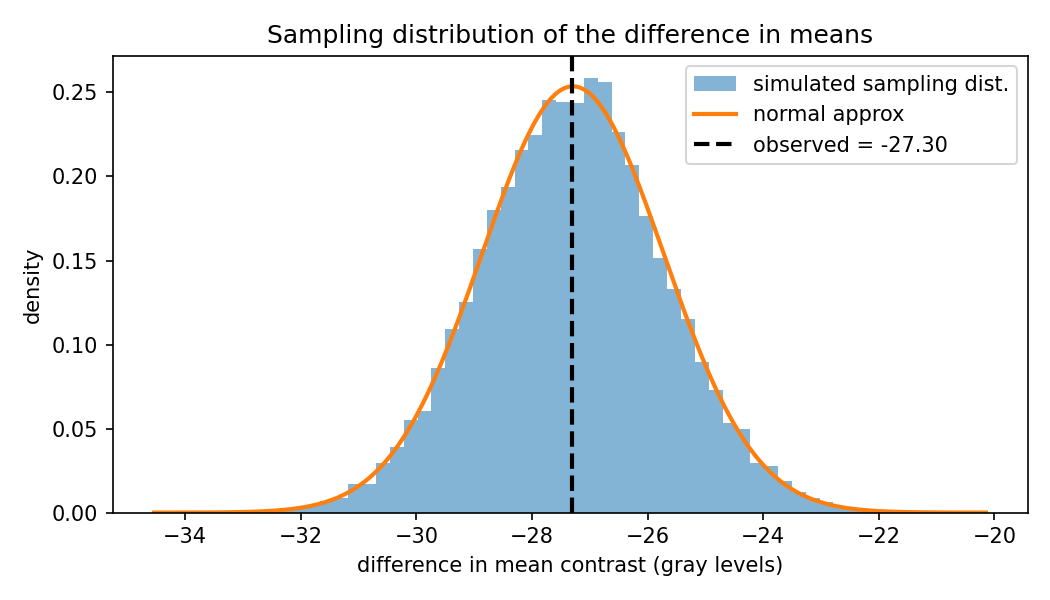


--- fig2_bootstrap_ci.png ---


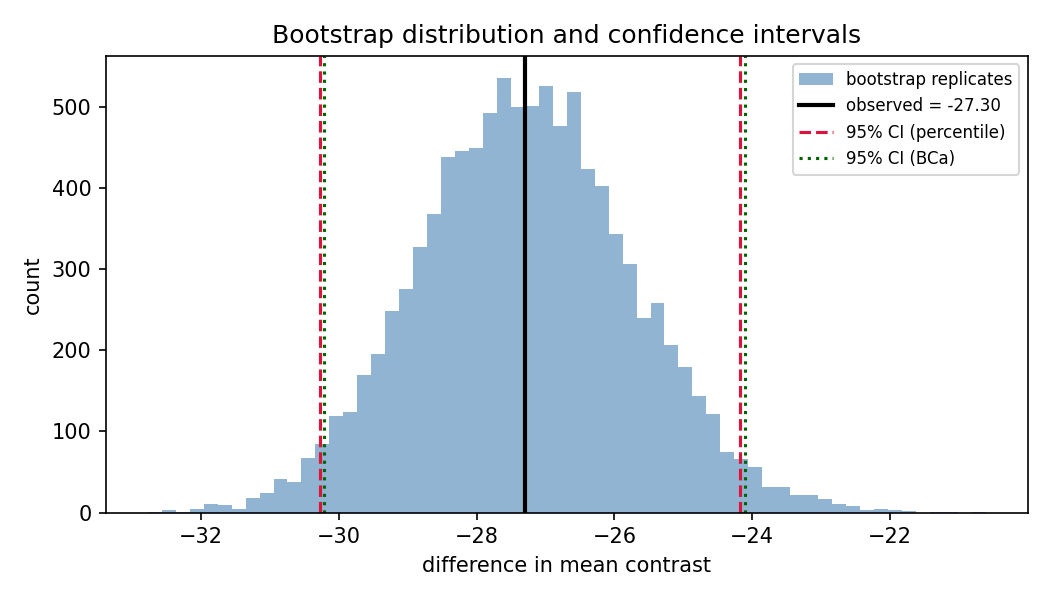


--- fig3_permutation_null.png ---


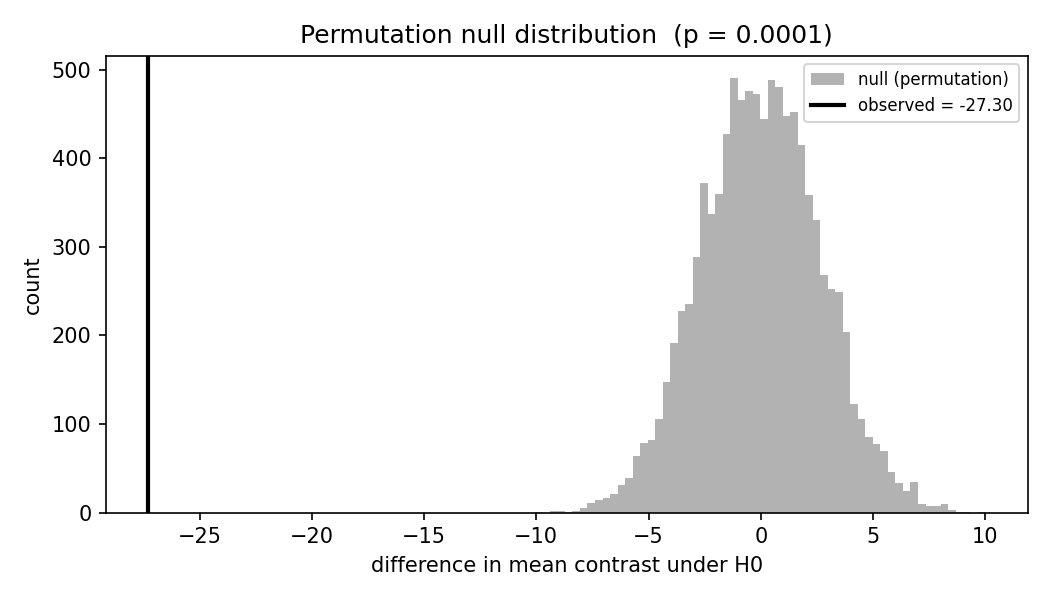


--- fig4_power_vs_n.png ---


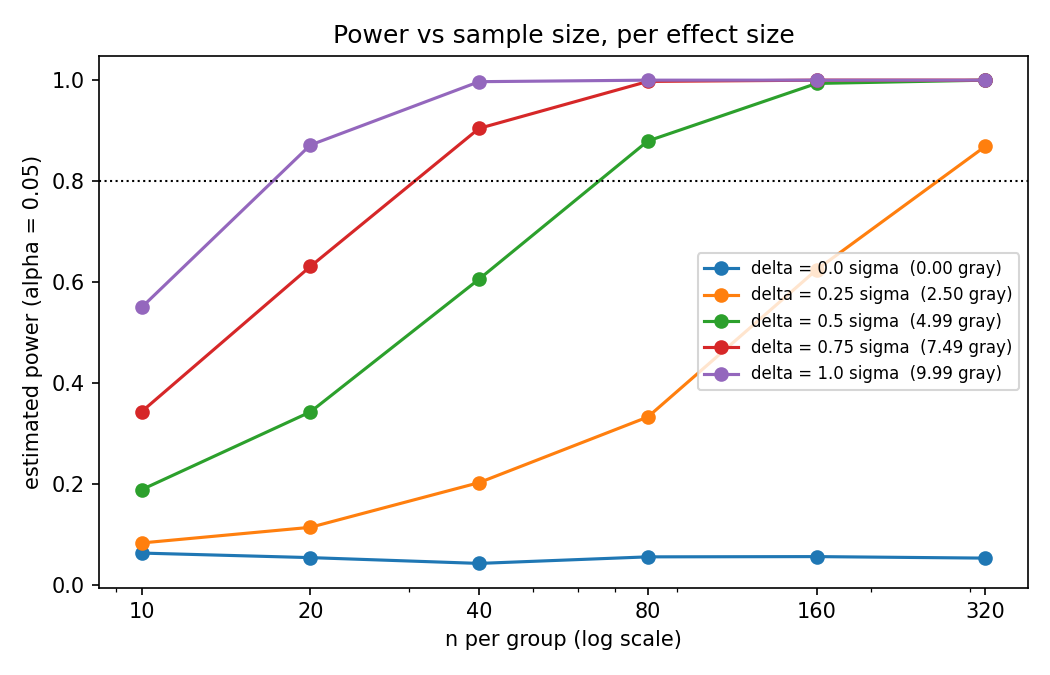


--- fig5_power_vs_noise.png ---


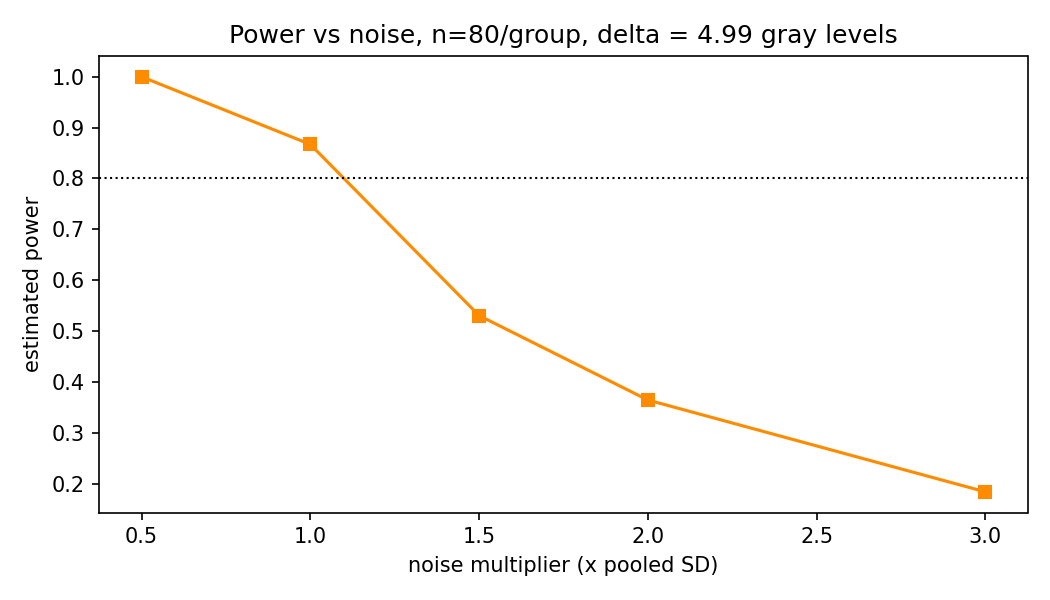


--- fig6_counterexample_images.png ---


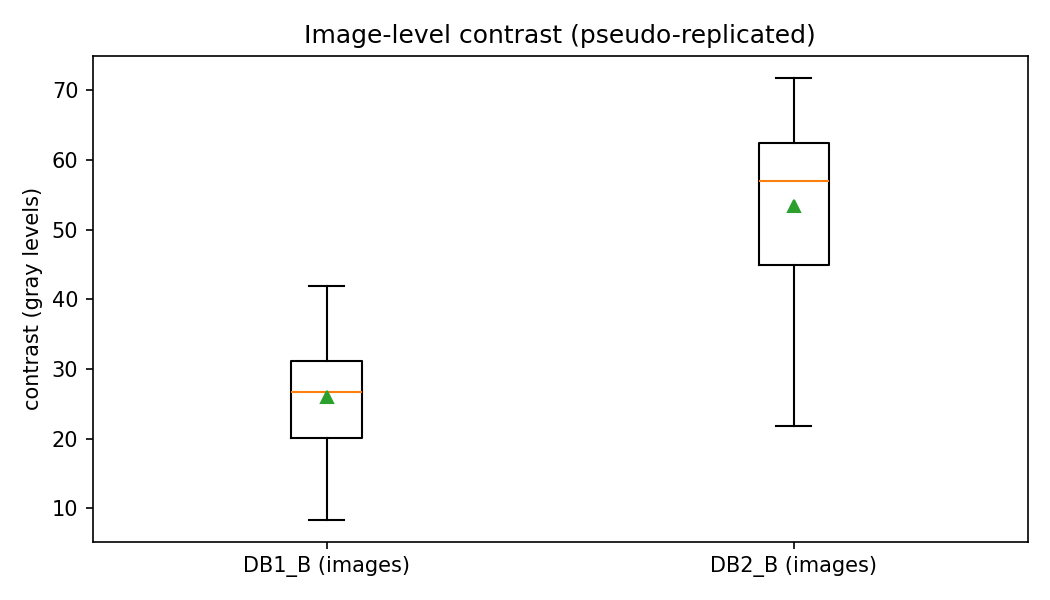


--- fig7_counterexample_fingers.png ---


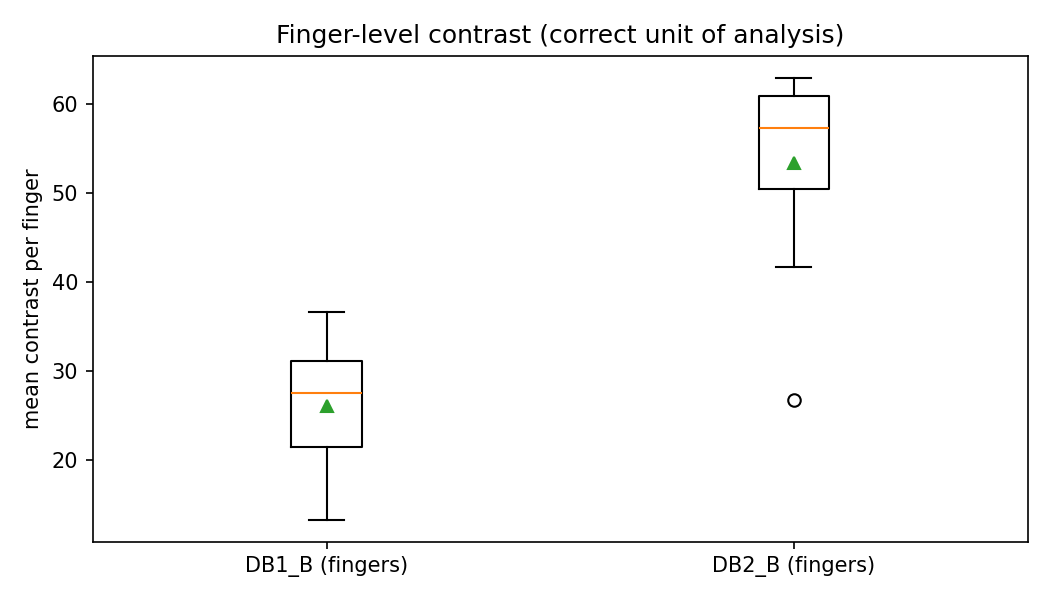

In [24]:
# Cell to verify and display saved figures
import os
from IPython.display import Image, display

figs = sorted(f for f in os.listdir("outputs") if f.endswith(".png"))
print("Found:", figs)

for f in figs:
    print(f"\n--- {f} ---")
    display(Image(filename=f"outputs/{f}"))